In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### EDA

In [2]:
df = pd.read_csv("Dataset.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


In [3]:
df.shape

(17379, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  casual      17379 non-null  object
 15  registered  17379 non-null  object
 16  cnt         17379 non-null  int64 
dtypes: int64(4), object(13)
memory usage: 2.3+ MB


In [5]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
(df.astype(str) == "?").sum().sum()

np.int64(48)

In [7]:
df = df.replace("?", np.nan)

In [8]:
(df.astype(str) == "?").sum().sum()

np.int64(0)

In [9]:
df.isnull().sum()

instant        0
dteday         0
season         6
yr             1
mnth           1
hr             0
holiday        1
weekday        0
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
cnt            0
dtype: int64

In [10]:
df.dtypes

instant        int64
dteday        object
season        object
yr            object
mnth          object
hr             int64
holiday       object
weekday        int64
workingday    object
weathersit    object
temp          object
atemp         object
hum           object
windspeed     object
casual        object
registered    object
cnt            int64
dtype: object

In [11]:
df = df.fillna(df.median(numeric_only=True))

In [12]:
for i in df.columns:
    if df[i].isnull().sum() > 0:
        df[i] = df[i].fillna(df[i].mode()[0])

In [13]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
cols = ['yr', 'mnth', 'temp', 'atemp', 'hum',
        'windspeed', 'casual', 'registered']

df[cols] = df[cols].astype(float)

In [16]:
df.dtypes

instant         int64
dteday         object
season         object
yr            float64
mnth          float64
hr              int64
holiday        object
weekday         int64
workingday     object
weathersit     object
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual        float64
registered    float64
cnt             int64
dtype: object

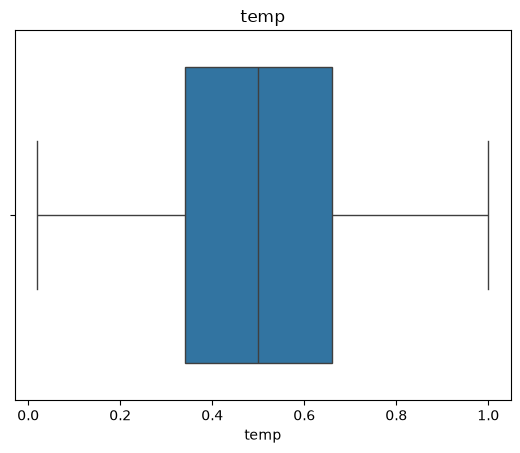

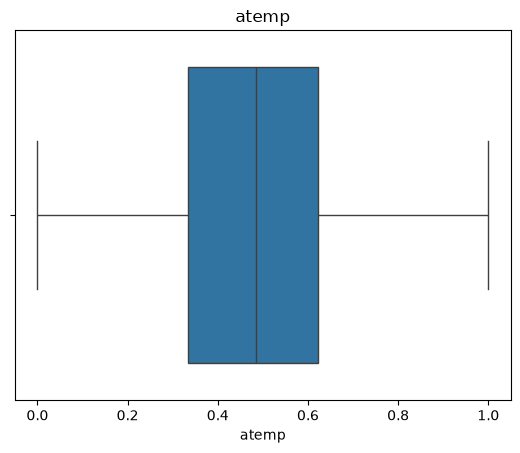

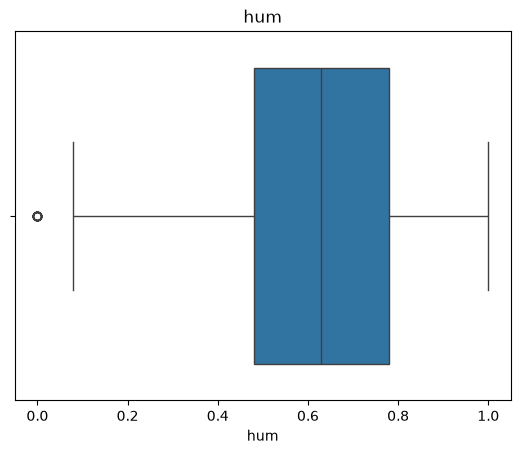

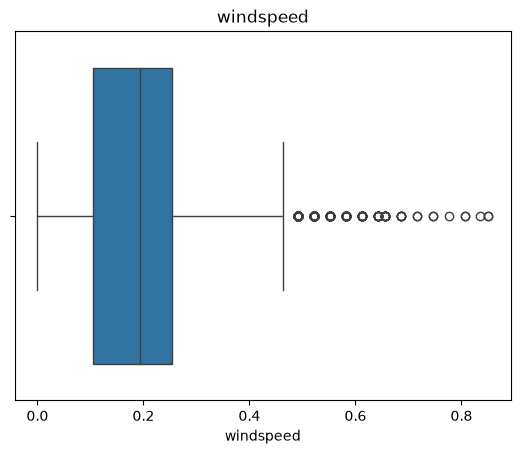

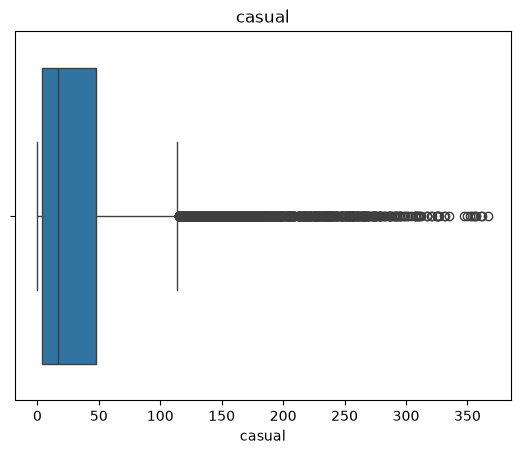

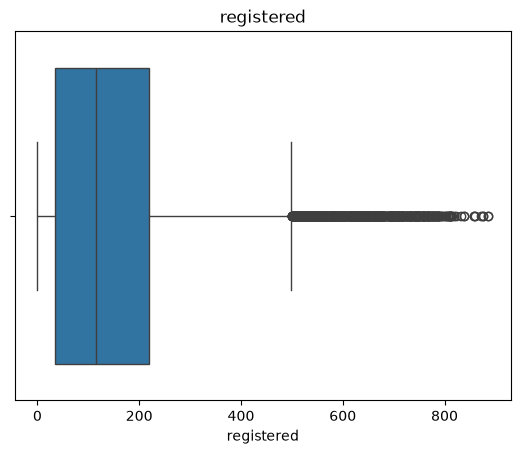

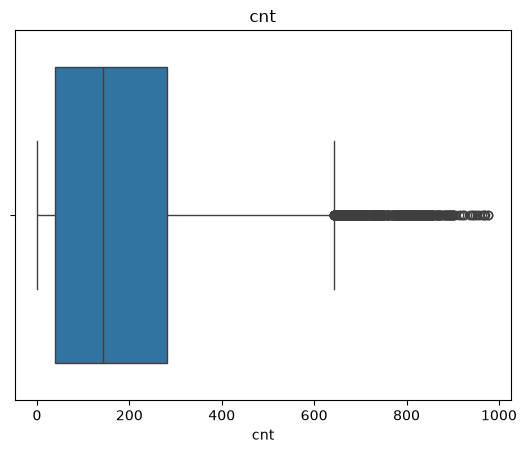

In [17]:
num_cols = [
    "temp", "atemp", "hum",
    "windspeed", "casual", "registered", "cnt"
]

for i in num_cols:
    sns.boxplot(x=df[i])
    plt.title(i)
    plt.show()

In [18]:
df[["windspeed", "casual", "registered", "cnt"]].describe()

,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.190025,35.674550,153.783935,189.463088
std,0.122345,49.305747,151.359696,181.387599
min,0.000000,0.000000,0.000000,1.000000
25%,0.104500,4.000000,34.000000,40.000000
50%,0.194000,17.000000,115.000000,142.000000
75%,0.253700,48.000000,220.000000,281.000000
max,0.850700,367.000000,886.000000,977.000000


In [19]:
df["dteday"] = pd.to_datetime(df['dteday'], dayfirst = True)

In [20]:
df["dteday"].dtype

dtype('<M8[ns]')

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  object        
 3   yr          17379 non-null  float64       
 4   mnth        17379 non-null  float64       
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  object        
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  object        
 9   weathersit  17379 non-null  object        
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  float64       
 15  registered  17379 non-null  float64       
 16  cnt         17379 non-

#### Data Visualization

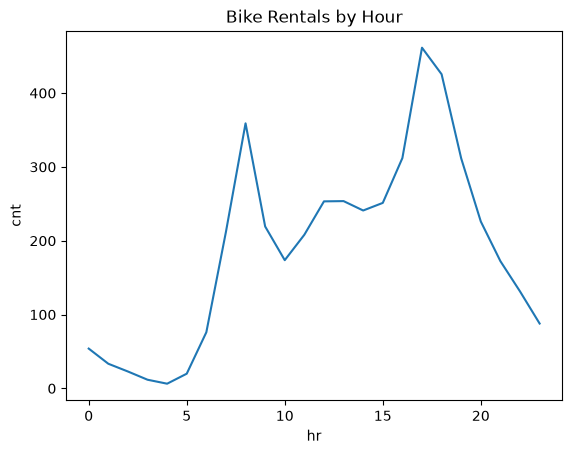

In [22]:
sns.lineplot(data=df, x='hr', y ='cnt',errorbar=None)
plt.title("Bike Rentals by Hour")
plt.show()

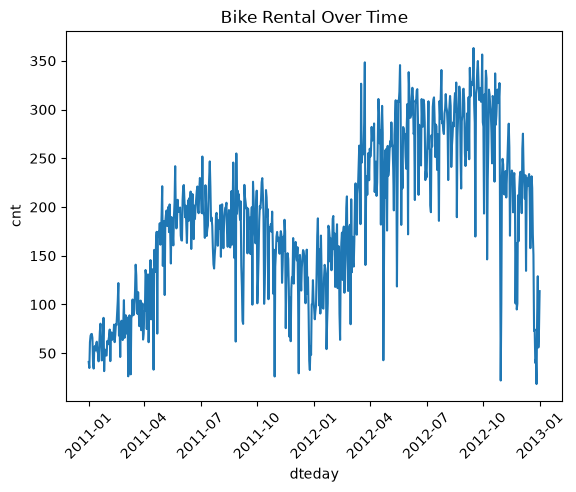

In [23]:
sns.lineplot(data=df, x= 'dteday',y= 'cnt',errorbar=None)
plt.title("Bike Rental Over Time")
plt.xticks(rotation=45)
plt.show()

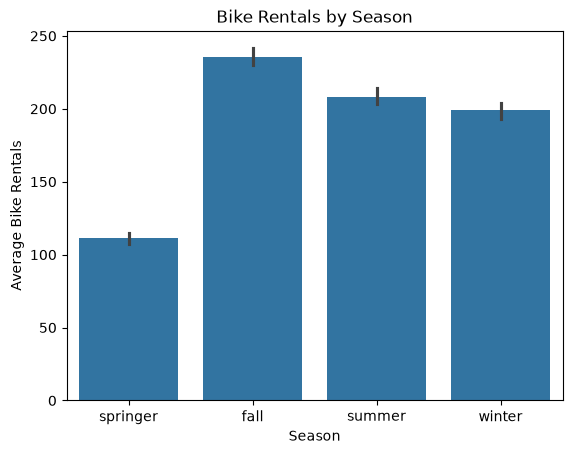

In [24]:
sns.barplot(data=df, x="season", y="cnt")
plt.title("Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Bike Rentals")
plt.show()

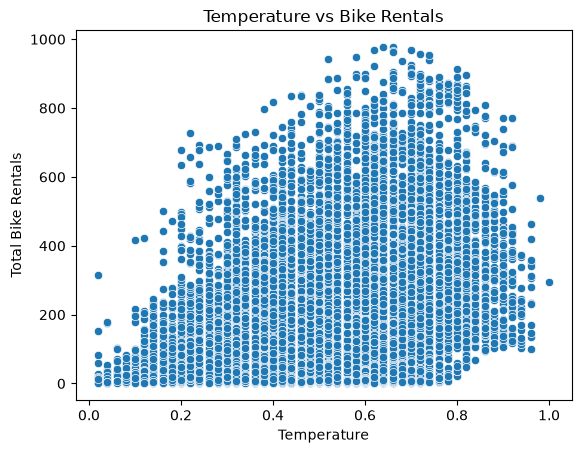

In [25]:
sns.scatterplot(data=df, x="temp", y="cnt")
plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Total Bike Rentals")
plt.show()

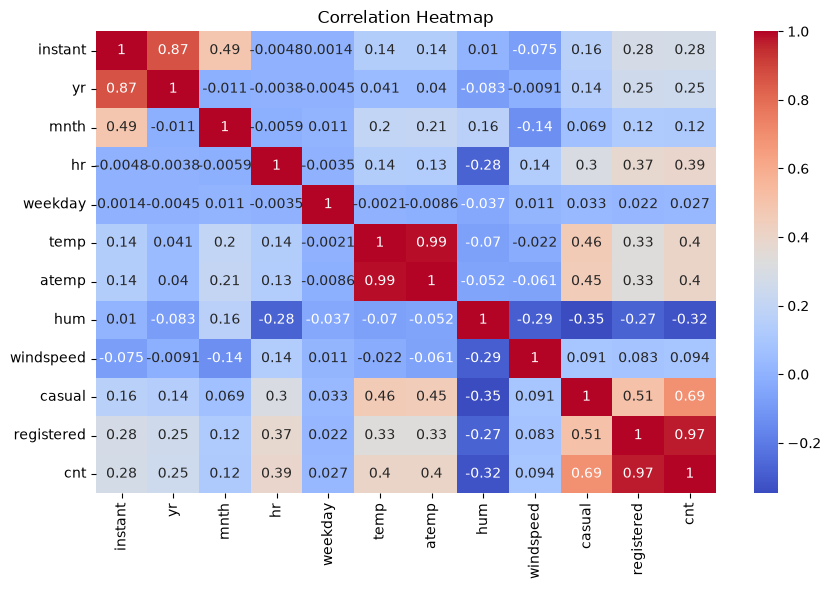

In [26]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

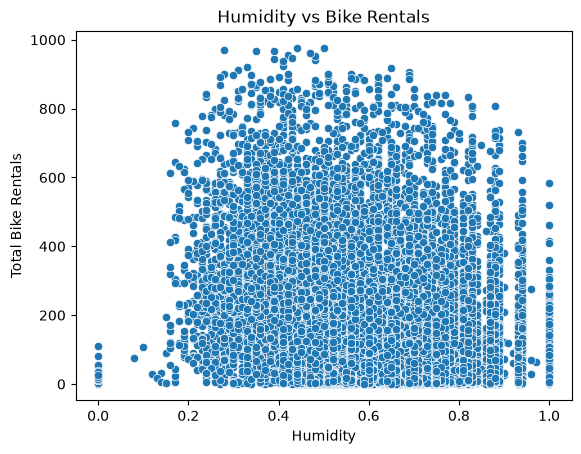

In [27]:
sns.scatterplot(data=df, x="hum", y="cnt")

plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Total Bike Rentals")

plt.show()

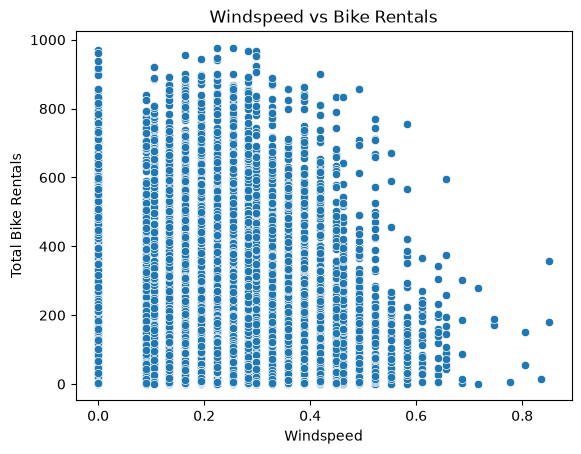

In [28]:
sns.scatterplot(data=df, x="windspeed", y="cnt")

plt.title("Windspeed vs Bike Rentals")
plt.xlabel("Windspeed")
plt.ylabel("Total Bike Rentals")

plt.show()

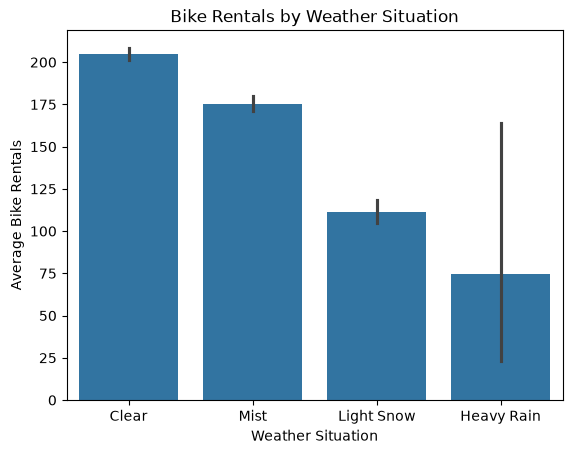

In [29]:
sns.barplot(data=df, x="weathersit", y="cnt")

plt.title("Bike Rentals by Weather Situation")
plt.xlabel("Weather Situation")
plt.ylabel("Average Bike Rentals")

plt.show()

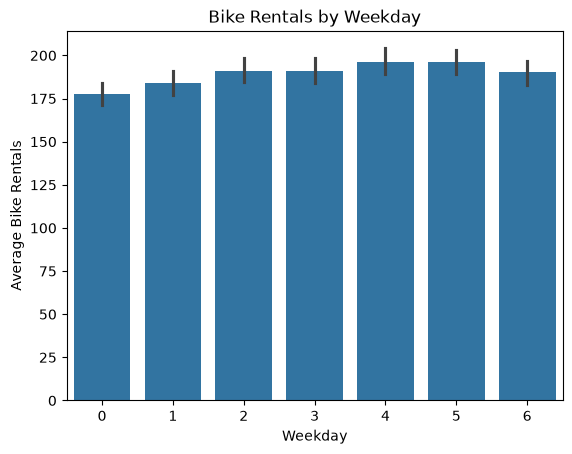

In [30]:
sns.barplot(data=df, x="weekday", y="cnt")

plt.title("Bike Rentals by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Bike Rentals")
plt.show()

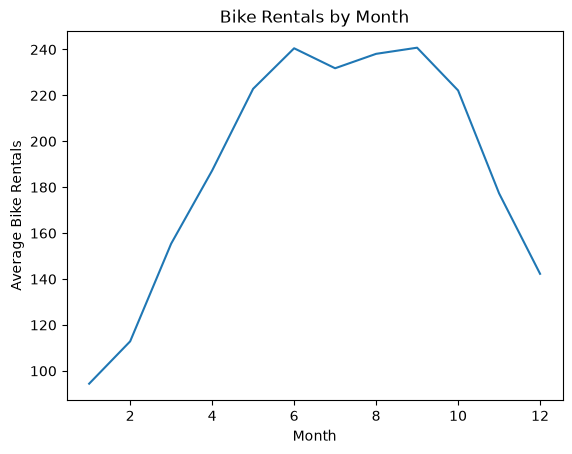

In [31]:
sns.lineplot(data=df, x="mnth", y="cnt", errorbar=None)

plt.title("Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Bike Rentals")
plt.show()

#### Feature Engineeing

In [32]:
df['day'] = df['dteday'].dt.day
df[['dteday','day']].head()

,dteday,day
0,2011-01-01,1
1,2011-01-01,1
2,2011-01-01,1
3,2011-01-01,1
4,2011-01-01,1


In [33]:
df["is_weekend"] = df["weekday"].isin([0,6]).astype(int)
df[["weekday","is_weekend"]].head(10)

,weekday,is_weekend
0,6,1
1,6,1
2,6,1
3,6,1
4,6,1
5,6,1
6,6,1
7,6,1
8,6,1
9,6,1


In [34]:
df[["weekday", "is_weekend"]].drop_duplicates()

,weekday,is_weekend
0,6,1
24,0,1
47,1,0
69,2,0
92,3,0
115,4,0
138,5,0


In [35]:
df.select_dtypes(include='object').columns

Index(['season', 'holiday', 'workingday', 'weathersit'], dtype='object')

In [36]:
for i in ["season", "holiday", "workingday", "weathersit"]:
    print(i,df[i].unique())

season ['springer' 'fall' 'summer' 'winter']
holiday ['No' 'Yes']
workingday ['No work' 'Working Day']
weathersit ['Clear' 'Mist' 'Light Snow' 'Heavy Rain']


In [37]:
df['season'].value_counts()

season
fall        4502
summer      4409
springer    4236
winter      4232
Name: count, dtype: int64

In [38]:
df['season'] = df['season'].replace('springer','spring')
df['season'].unique()

array(['spring', 'fall', 'summer', 'winter'], dtype=object)

In [39]:
df['holiday'].value_counts()

holiday
No     16879
Yes      500
Name: count, dtype: int64

In [40]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [41]:
le = LabelEncoder()

In [42]:
df['holiday'] = le.fit_transform(df['holiday'])

In [43]:
df['workingday'] = le.fit_transform(df['workingday'])

In [44]:
ohe = OneHotEncoder(sparse_output=False)

In [45]:
encoded = ohe.fit_transform(df[['season']])
encoded.shape

(17379, 4)

In [46]:
encoded_df = pd.DataFrame(encoded, 
                          columns = ohe.get_feature_names_out(['season']),
                          index=df.index
)
df = pd.concat([df,encoded_df],axis=1)
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,windspeed,casual,registered,cnt,day,is_weekend,season_fall,season_spring,season_summer,season_winter
0,1,2011-01-01,spring,2011.0,1.0,0,0,6,0,Clear,...,0.0,3.0,13.0,16,1,1,0.0,1.0,0.0,0.0
1,2,2011-01-01,spring,2011.0,1.0,1,0,6,0,Clear,...,0.0,8.0,32.0,40,1,1,0.0,1.0,0.0,0.0
2,3,2011-01-01,spring,2011.0,1.0,2,0,6,0,Clear,...,0.0,5.0,27.0,32,1,1,0.0,1.0,0.0,0.0
3,4,2011-01-01,spring,2011.0,1.0,3,0,6,0,Clear,...,0.0,3.0,10.0,13,1,1,0.0,1.0,0.0,0.0
4,5,2011-01-01,spring,2011.0,1.0,4,0,6,0,Clear,...,0.0,0.0,1.0,1,1,1,0.0,1.0,0.0,0.0


In [47]:
df.drop('season',axis=1, inplace=True)
df.head()

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,windspeed,casual,registered,cnt,day,is_weekend,season_fall,season_spring,season_summer,season_winter
0,1,2011-01-01,2011.0,1.0,0,0,6,0,Clear,0.24,...,0.0,3.0,13.0,16,1,1,0.0,1.0,0.0,0.0
1,2,2011-01-01,2011.0,1.0,1,0,6,0,Clear,0.22,...,0.0,8.0,32.0,40,1,1,0.0,1.0,0.0,0.0
2,3,2011-01-01,2011.0,1.0,2,0,6,0,Clear,0.22,...,0.0,5.0,27.0,32,1,1,0.0,1.0,0.0,0.0
3,4,2011-01-01,2011.0,1.0,3,0,6,0,Clear,0.24,...,0.0,3.0,10.0,13,1,1,0.0,1.0,0.0,0.0
4,5,2011-01-01,2011.0,1.0,4,0,6,0,Clear,0.24,...,0.0,0.0,1.0,1,1,1,0.0,1.0,0.0,0.0


In [48]:
weather_encoded = ohe.fit_transform(df[["weathersit"]])

weather_df = pd.DataFrame(
    weather_encoded,
    columns=ohe.get_feature_names_out(["weathersit"]),
    index=df.index
)

df = pd.concat([df, weather_df], axis=1)

df.head()

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,day,is_weekend,season_fall,season_spring,season_summer,season_winter,weathersit_Clear,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,1,2011-01-01,2011.0,1.0,0,0,6,0,Clear,0.24,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2,2011-01-01,2011.0,1.0,1,0,6,0,Clear,0.22,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,3,2011-01-01,2011.0,1.0,2,0,6,0,Clear,0.22,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,4,2011-01-01,2011.0,1.0,3,0,6,0,Clear,0.24,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,5,2011-01-01,2011.0,1.0,4,0,6,0,Clear,0.24,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [49]:
df.drop("weathersit", axis=1, inplace=True)
df.head()

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,day,is_weekend,season_fall,season_spring,season_summer,season_winter,weathersit_Clear,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,1,2011-01-01,2011.0,1.0,0,0,6,0,0.24,0.2879,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2,2011-01-01,2011.0,1.0,1,0,6,0,0.22,0.2727,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,3,2011-01-01,2011.0,1.0,2,0,6,0,0.22,0.2727,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,4,2011-01-01,2011.0,1.0,3,0,6,0,0.24,0.2879,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,5,2011-01-01,2011.0,1.0,4,0,6,0,0.24,0.2879,...,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   instant                17379 non-null  int64         
 1   dteday                 17379 non-null  datetime64[ns]
 2   yr                     17379 non-null  float64       
 3   mnth                   17379 non-null  float64       
 4   hr                     17379 non-null  int64         
 5   holiday                17379 non-null  int64         
 6   weekday                17379 non-null  int64         
 7   workingday             17379 non-null  int64         
 8   temp                   17379 non-null  float64       
 9   atemp                  17379 non-null  float64       
 10  hum                    17379 non-null  float64       
 11  windspeed              17379 non-null  float64       
 12  casual                 17379 non-null  float64       
 13  r

##### spliting data into training and testing

In [51]:
X = df.drop(['cnt','casual','registered','instant','dteday'], axis=1)
y = df['cnt']

print(X.shape)
print(y.shape)

(17379, 20)
(17379,)


In [52]:
from sklearn.model_selection import train_test_split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13903, 20), (3476, 20), (13903,), (3476,))

In [54]:
from sklearn.preprocessing import StandardScaler

In [55]:
scaler = StandardScaler()

In [56]:
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [57]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(13903, 20)
(3476, 20)


#### Model Building

##### 1. Decision Tree

In [58]:
from sklearn.tree import DecisionTreeRegressor

In [59]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [60]:
y_pred_dt = dt_model.predict(X_test)
y_pred_dt[:10]

array([423., 103.,  12., 395.,  12.,  29., 704.,  26.,   9.,  24.])

##### Decision Tree Evaluation

In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [62]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

MAE: 35.02215189873418
MSE: 3641.3311277330263
RMSE: 60.34344312129551
R2 Score: 0.8850060373748967


##### 2. Random Forest

In [63]:
from sklearn.ensemble import RandomForestRegressor

In [64]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [65]:
y_pred_rf = rf_model.predict(X_test)
y_pred_rf[:10]

array([402.73, 106.44,  10.34, 520.33,  15.55,  36.59, 713.64,  38.63,
         9.86,  25.27])

##### Random Forest Evaluation

In [66]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

MAE: 24.55148734177215
MSE: 1717.4007300057538
RMSE: 41.44153387612184
R2 Score: 0.9457641427184464


##### 3. GradientBoostingRegressor

In [67]:
from sklearn.ensemble import GradientBoostingRegressor

In [68]:
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [69]:
y_pred_gb = gb_model.predict(X_test)
y_pred_gb[:10]

array([468.14829035, 120.49562073,  31.34620403, 511.67976042,
         9.19484417,  24.40358839, 657.7276623 ,  93.13160819,
        25.23771828,  20.96408377])

##### Gradient Boosting Evalution

In [70]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

MAE: 47.18235145980951
MSE: 4805.941235306001
RMSE: 69.32489621561652
R2 Score: 0.8482274181048497


##### 4. Linear Regression

In [71]:
from sklearn.linear_model import LinearRegression

In [72]:
lr_model =  LinearRegression()

In [73]:
lr_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](20,)","[40.66, 0.47,51.86,..., 0.52,-6.9 , 3.82]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,190.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(18)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](20,)","[208.84,179.6 ,166.9 ,..., 2.09, 0. , 0. ]"


In [74]:
y_pred_lr = lr_model.predict(X_test_scaled)

##### Linear Regression Evaluation

In [75]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression
MAE: 103.7164799976811
MSE: 19014.688361861037
RMSE: 137.89375751592615
R2 Score: 0.399512352458557


##### 5. K-Nearest Neighbors (KNN)

In [76]:
from sklearn.neighbors import KNeighborsRegressor

In [77]:
knn_model = KNeighborsRegressor(n_neighbors=5)

In [78]:
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [79]:
y_pred_knn = knn_model.predict(X_test_scaled)

##### K-Nearest Neighbors (KNN) Evaluation

In [80]:
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN Regression")
print("MAE:", mae_knn)
print("MSE:", mse_knn)
print("RMSE:", rmse_knn)
print("R2 Score:", r2_knn)

KNN Regression
MAE: 80.20667433831991
MSE: 13695.839769850405
RMSE: 117.02922613539921
R2 Score: 0.5674826508859452


##### 6. Support Vector Regression (SVR)

In [81]:
from sklearn.svm import SVR

In [82]:
svr_model = SVR()

In [83]:
svr_model.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [84]:
y_pred_svr = svr_model.predict(X_test_scaled)

#####  Support Vector Regression (SVR) Evaluation

In [85]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("Support Vector Regression")
print("MAE:", mae_svr)
print("MSE:", mse_svr)
print("RMSE:", rmse_svr)
print("R2 Score:", r2_svr)

Support Vector Regression
MAE: 92.92616051995728
MSE: 20250.381898993273
RMSE: 142.30383655753374
R2 Score: 0.36048890431817027


#### Hyperparameter Tuning

In [86]:
from sklearn.model_selection import GridSearchCV

In [87]:
# 1. Decision Tree
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [5, 10, 20]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# 2. Random Forest
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {"n_estimators": [50, 100], "max_depth": [10, None]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# 3. Gradient Boosting
gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
# 4. Linear Regression
lr_grid = GridSearchCV(
    LinearRegression(),
    {"fit_intercept": [True, False]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# 5. KNN
knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    {"n_neighbors": [3, 5, 7, 9, 11]},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
# 6. SVR
svr_grid = GridSearchCV(
    SVR(),
    {
        "C": [1, 10, 100],
        "epsilon": [0.1, 0.2]
    },
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train and tune all three models
dt_grid.fit(X_train, y_train)
rf_grid.fit(X_train, y_train)
gb_grid.fit(X_train, y_train)
lr_grid.fit(X_train_scaled, y_train)
knn_grid.fit(X_train_scaled, y_train)
svr_grid.fit(X_train_scaled, y_train)

print("Decision Tree Best Parameters:", dt_grid.best_params_)
print("Random Forest Best Parameters:", rf_grid.best_params_)
print("Gradient Boosting Best Parameters:", gb_grid.best_params_)
print("Linear Regression Best Parameters:", lr_grid.best_params_)
print("KNN Best Parameters:", knn_grid.best_params_)
print("SVR Best Parameters:", svr_grid.best_params_)

Decision Tree Best Parameters: {'max_depth': 10}
Random Forest Best Parameters: {'max_depth': None, 'n_estimators': 100}
Gradient Boosting Best Parameters: {'learning_rate': 0.1, 'n_estimators': 100}
Linear Regression Best Parameters: {'fit_intercept': True}
KNN Best Parameters: {'n_neighbors': 7}
SVR Best Parameters: {'C': 100, 'epsilon': 0.2}


In [88]:
# Predictions using tuned models
y_pred_dt_tuned = dt_grid.predict(X_test)

y_pred_rf_tuned = rf_grid.predict(X_test)

y_pred_gb_tuned = gb_grid.predict(X_test)

y_pred_lr_tuned = lr_grid.predict(X_test_scaled)

y_pred_knn_tuned = knn_grid.predict(X_test_scaled)

y_pred_svr_tuned = svr_grid.predict(X_test_scaled)

#### Model Evaluation Comparison Table

In [89]:
# Decision Tree
mae_dt_tuned = mean_absolute_error(y_test, y_pred_dt_tuned)
mse_dt_tuned = mean_squared_error(y_test, y_pred_dt_tuned)
rmse_dt_tuned = np.sqrt(mse_dt_tuned)
r2_dt_tuned = r2_score(y_test, y_pred_dt_tuned)

# Random Forest
mae_rf_tuned = mean_absolute_error(y_test, y_pred_rf_tuned)
mse_rf_tuned = mean_squared_error(y_test, y_pred_rf_tuned)
rmse_rf_tuned = np.sqrt(mse_rf_tuned)
r2_rf_tuned = r2_score(y_test, y_pred_rf_tuned)

# Gradient Boosting
mae_gb_tuned = mean_absolute_error(y_test, y_pred_gb_tuned)
mse_gb_tuned = mean_squared_error(y_test, y_pred_gb_tuned)
rmse_gb_tuned = np.sqrt(mse_gb_tuned)
r2_gb_tuned = r2_score(y_test, y_pred_gb_tuned)

# Linear Regression
mae_lr_tuned = mean_absolute_error(y_test, y_pred_lr_tuned)
mse_lr_tuned = mean_squared_error(y_test, y_pred_lr_tuned)
rmse_lr_tuned = np.sqrt(mse_lr_tuned)
r2_lr_tuned = r2_score(y_test, y_pred_lr_tuned)

# KNN
mae_knn_tuned = mean_absolute_error(y_test, y_pred_knn_tuned)
mse_knn_tuned = mean_squared_error(y_test, y_pred_knn_tuned)
rmse_knn_tuned = np.sqrt(mse_knn_tuned)
r2_knn_tuned = r2_score(y_test, y_pred_knn_tuned)

# SVR
mae_svr_tuned = mean_absolute_error(y_test, y_pred_svr_tuned)
mse_svr_tuned = mean_squared_error(y_test, y_pred_svr_tuned)
rmse_svr_tuned = np.sqrt(mse_svr_tuned)
r2_svr_tuned = r2_score(y_test, y_pred_svr_tuned)

In [90]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest", "Gradient Boosting", "KNN", "SVR", "Linear Regression"],
    "MAE": [mae_dt_tuned, mae_rf_tuned, mae_gb_tuned, mae_knn_tuned, mae_svr_tuned, mae_lr_tuned],
    "MSE": [mse_dt_tuned, mse_rf_tuned, mse_gb_tuned, mse_knn_tuned, mse_svr_tuned, mse_lr_tuned],
    "RMSE": [rmse_dt_tuned, rmse_rf_tuned, rmse_gb_tuned, rmse_knn_tuned, rmse_svr_tuned, rmse_lr_tuned ],
    "R2 Score": [r2_dt_tuned, r2_rf_tuned, r2_gb_tuned, r2_knn_tuned, r2_svr_tuned, r2_lr_tuned]
})
results

,Model,MAE,MSE,RMSE,R2 Score
0,Decision Tree,35.906158,3409.090581,58.387418,0.892340
1,Random Forest,24.551487,1717.400730,41.441534,0.945764
2,Gradient Boosting,47.182351,4805.941235,69.324896,0.848227
3,KNN,81.948175,13522.283125,116.285352,0.572964
4,SVR,74.059843,13687.364848,116.993012,0.567750
5,Linear Regression,103.716480,19014.688362,137.893758,0.399512


#### Deployment

In [91]:
import joblib

In [92]:
best_model = rf_grid.best_estimator_

In [93]:
joblib.dump(best_model, "bike_sharing_model.pkl")

['bike_sharing_model.pkl']

In [94]:
joblib.dump(X_train.columns.tolist(), "bike_sharing_features.pkl")

['bike_sharing_features.pkl']

In [95]:
loaded_model = joblib.load("bike_sharing_model.pkl")
loaded_features = joblib.load("bike_sharing_features.pkl")

print("Model loaded successfully!")
print("Number of features:", len(loaded_features))

Model loaded successfully!
Number of features: 20


In [96]:
sample_data = X_test.iloc[[0]]
prediction = loaded_model.predict(sample_data)

print("Predicted Bike Rentals:", prediction[0])
print("Actual Bike Rentals:", y_test.iloc[0])

Predicted Bike Rentals: 402.73
Actual Bike Rentals: 425


#### Streamlit

In [100]:

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# 1. Load saved model and feature names
model = joblib.load("bike_sharing_model.pkl")
features = joblib.load("bike_sharing_features.pkl")

# 2. Application title
st.title("Bike Sharing Rental Prediction")

st.write(
    "Enter the details below to predict bike rental demand."
)

st.success("Machine Learning Model Loaded Successfully!")

st.divider()

# 3. Date and time details
st.header("Date and Time Details")

yr = st.selectbox(
    "Select Year",
    options=[0, 1],
    format_func=lambda x: "2011" if x == 0 else "2012"
)

mnth = st.selectbox(
    "Select Month",
    options=list(range(1, 13))
)

hr = st.slider(
    "Select Hour",
    min_value=0,
    max_value=23,
    value=12
)

weekday = st.selectbox(
    "Select Weekday",
    options=list(range(7)),
    format_func=lambda x: [
        "Sunday", "Monday", "Tuesday",
        "Wednesday", "Thursday",
        "Friday", "Saturday"
    ][x]
)

day = st.number_input(
    "Enter Day of Month",
    min_value=1,
    max_value=31,
    value=15
)

# Automatically calculate weekend
is_weekend = 1 if weekday in [0, 6] else 0

st.divider()

# 4. Holiday and working day
st.header("Working Day Details")

holiday_choice = st.selectbox(
    "Is it a Holiday?",
    ["No", "Yes"]
)

workingday_choice = st.selectbox(
    "Is it a Working Day?",
    ["No work", "Working Day"]
)

# Label encoding
holiday = 0 if holiday_choice == "No" else 1

workingday = (
    0 if workingday_choice == "No work" else 1
)

st.divider()

# 5. Weather details
st.header("Weather Details")

temp = st.slider(
    "Temperature",
    0.0, 1.0, 0.5
)

atemp = st.slider(
    "Feels Like Temperature",
    0.0, 1.0, 0.5
)

hum = st.slider(
    "Humidity",
    0.0, 1.0, 0.5
)

windspeed = st.slider(
    "Wind Speed",
    0.0, 1.0, 0.2
)

st.divider()

# 6. Season and weather condition
st.header("Season and Weather Conditions")

season = st.selectbox(
    "Select Season",
    ["fall", "spring", "summer", "winter"]
)

weathersit = st.selectbox(
    "Select Weather Condition",
    ["Clear", "Heavy Rain", "Light Snow", "Mist"]
)

st.divider()

# 7. Prepare all 20 features

input_data = {
    "yr": yr,
    "mnth": mnth,
    "hr": hr,
    "holiday": holiday,
    "weekday": weekday,
    "workingday": workingday,
    "temp": temp,
    "atemp": atemp,
    "hum": hum,
    "windspeed": windspeed,
    "day": day,
    "is_weekend": is_weekend,

    # Season One-Hot Encoding
    "season_fall": 1 if season == "fall" else 0,
    "season_spring": 1 if season == "spring" else 0,
    "season_summer": 1 if season == "summer" else 0,
    "season_winter": 1 if season == "winter" else 0,

    # Weather One-Hot Encoding
    "weathersit_Clear": 1 if weathersit == "Clear" else 0,
    "weathersit_Heavy Rain": 1 if weathersit == "Heavy Rain" else 0,
    "weathersit_Light Snow": 1 if weathersit == "Light Snow" else 0,
    "weathersit_Mist": 1 if weathersit == "Mist" else 0
}

# Check whether all model features are available
missing_features = [
    col for col in features if col not in input_data
]

if missing_features:
    st.error(
        f"Missing model features: {missing_features}"
    )

else:

    # Arrange features in the original training order
    input_df = pd.DataFrame(
        [[input_data[col] for col in features]],
        columns=features
    )

    st.divider()

    # 8. Prediction
    st.header("Bike Rental Prediction")

    if st.button("Predict Bike Rentals"):

        prediction = model.predict(input_df)

        predicted_count = max(0, round(prediction[0]))

        st.success(
            f"Predicted Bike Rentals: {predicted_count}"
        )

        st.write(
            "This is the estimated number of bikes "
            "that may be rented."
        )


Writing app.py


In [98]:
import os

print("Current Folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))
print("app.py is file:", os.path.isfile("app.py"))

print("Folder writable:", os.access(os.getcwd(), os.W_OK))

Current Folder: C:\Users\DELL
app.py exists: True
app.py is file: False
Folder writable: True


In [99]:
import os

os.rename("app.py", "app_backup")
print("Folder renamed successfully")

Folder renamed successfully


In [101]:
print("app.py is file:", os.path.isfile("app.py"))

app.py is file: True


In [104]:
import os

files = [
    "app.py",
    "bike_sharing_model.pkl",
    "bike_sharing_features.pkl"
]

for file in files:
    print(file, "->", os.path.exists(file))

app.py -> True
bike_sharing_model.pkl -> True
bike_sharing_features.pkl -> True


https://bikesharingdeployment-l6ghssjntbzpkqsyfjy9ab.streamlit.app/